In [ ]:
#BIBLIOTEKI
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
import numpy as np 
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_log_error, make_scorer

from xgboost import XGBRegressor


In [ ]:
#ODCZYT i ILOSC PUSTYCH WARTOSCI
#V Basen PoolQC - brak basenu
#V Garaż GarageType, GarageQual, GarageCond, GarageFinish, GarageYrBlt -- brak garażu
#V Piwnica BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmFinType2 - brak piwnicy
#V MiscFeature, Alley, Fence, FireplaceQu - brak elementu
#V Eleweacja  MasVnrType, MasVnrArea - brak okładziny lub inforamcji
#Działka - LosFrontage -- Nieznana wartość poprostu, trzeba neistety mediana w obrębie neighboordhood
#Pojedyncze braki MSZoning, Utilities, Functional, SaleType, 

test_csv = pd.read_csv("../data/test.csv")
train_csv = pd.read_csv("../data/train.csv")
missing_test = test_csv.isnull().mean() * 100
missing_train = train_csv.isnull().mean() * 100
print(missing_test[missing_test > 0].sort_values(ascending=False))
print(missing_train[missing_train > 0].sort_values(ascending=False))


PoolQC          99.794380
MiscFeature     96.504455
Alley           92.666210
Fence           80.123372
MasVnrType      61.274846
FireplaceQu     50.034270
LotFrontage     15.558602
GarageQual       5.346127
GarageCond       5.346127
GarageYrBlt      5.346127
GarageFinish     5.346127
GarageType       5.209047
BsmtCond         3.084304
BsmtQual         3.015764
BsmtExposure     3.015764
BsmtFinType1     2.878684
BsmtFinType2     2.878684
MasVnrArea       1.028101
MSZoning         0.274160
Functional       0.137080
BsmtFullBath     0.137080
Utilities        0.137080
BsmtHalfBath     0.137080
Exterior1st      0.068540
Exterior2nd      0.068540
TotalBsmtSF      0.068540
BsmtUnfSF        0.068540
BsmtFinSF2       0.068540
BsmtFinSF1       0.068540
KitchenQual      0.068540
GarageArea       0.068540
GarageCars       0.068540
SaleType         0.068540
dtype: float64
PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.7260

In [ ]:
#Garaż
categorical_garage = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

for df in [train_csv, test_csv]:
    df[categorical_garage] = df[categorical_garage].fillna("None")
    df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)

#Piwnica
bsmt_cat = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]
bsmt_num = [
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath"
]

for df in [train_csv, test_csv]:
    df[bsmt_cat] = df[bsmt_cat].fillna("None")
    df[bsmt_num] = df[bsmt_num].fillna(0)

#Uzupelnienie braki
for df in [train_csv, test_csv]:
    none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType"]
    df[none_cols] = df[none_cols].fillna("None")

    df["MasVnrArea"]=df["MasVnrArea"].fillna(0)

    garage_num=["GarageYrBlt", "GarageArea", "GarageCars"]
    df[garage_num] = df[garage_num].fillna(0)



#Uzupełnienie braków jakichś przez moda(najczęściej występująca wartość) dla kolumn kategorycznych
mode_cols = [
    "MSZoning",
    "Utilities",
    "Exterior1st",
    "Exterior2nd",
    "KitchenQual",
    "SaleType",
    "Electrical"
]
for col in mode_cols:
    mode_value = train_csv[col].mode()[0]

    train_csv[col] = train_csv[col].fillna(mode_value)
    test_csv[col] = test_csv[col].fillna(mode_value)
train_csv["Functional"] = train_csv["Functional"].fillna("Typ")
test_csv["Functional"] = test_csv["Functional"].fillna("Typ")


#Uzupelnienie pustego LotFrontage przez medianę w obrębie Neighborhood bo dizelnice mogą mieć różne wartości

neighborhood_medians = train_csv.groupby("Neighborhood")["LotFrontage"].median()
global_median = train_csv["LotFrontage"].median()
for df in [train_csv, test_csv]:
    df["LotFrontage"] = (
        df["LotFrontage"].fillna(df["Neighborhood"].map(neighborhood_medians)).fillna(global_median)
    )

print(test_csv.isnull().sum()[test_csv.isnull().sum() > 0])



Series([], dtype: int64)


In [ ]:
#Duplikaty
print(train_csv.duplicated().sum()) #0
print(test_csv.duplicated().sum()) #0
# print(train_csv.describe().T)

#USUWANIE OUTLIEROW
numeric_cols = train_csv.select_dtypes(include="number").columns
numeric_cols = numeric_cols.drop("Id")
outlier_report =[]
for col in numeric_cols:
    Q1=train_csv[col].quantile(0.25)
    Q3=train_csv[col].quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR
    outliers=train_csv[(train_csv[col]<lower_bound) | (train_csv[col]>upper_bound)]

    outlier_report.append({
        "Column": col,
        "Outliers": len(outliers),
        "Percentage": round(len(outliers) / len(train_csv) * 100, 2),
        "Min": train_csv[col].min(),
        "Max": train_csv[col].max(),
        "Upper_Bound": round(upper_bound, 2)
    })
outlier_df = pd.DataFrame(outlier_report)

outlier_df = outlier_df.sort_values(
    "Percentage", ascending=False
)
# print(outlier_df.to_string(index=False))    


0
0


In [ ]:
#Feature Engineering
for df in [train_csv, test_csv]:
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"] #powierhnia mieszkania 
    df["TotalPorchSF"] = (#powierzchnia mieszkania z gankiem i innymi duperelami
        df["OpenPorchSF"]
        + df["3SsnPorch"]
        + df["EnclosedPorch"]
        + df["ScreenPorch"]
        + df["WoodDeckSF"]
    )
    df["TotalBathrooms"] = ( #wszystkie lazienki w domu
        df["FullBath"] +
        0.5 * df["HalfBath"] +
        df["BsmtFullBath"] +
        0.5 * df["BsmtHalfBath"]
    )
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["YearsSinceRemod"] = df["YrSold"] - df["YearRemodAdd"]
    df["HasGarage"] = (df["GarageCars"] > 0).astype(int)
    df["HasBsmt"] = (df["TotalBsmtSF"] > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)

    df["GarageAge"] = (
    df["YrSold"] - df["GarageYrBlt"]
)

    df.loc[df["GarageYrBlt"] == 0, "GarageAge"] = 0

new_features = [
    "TotalSF",
    "TotalPorchSF",
    "TotalBathrooms",
    "HouseAge",
    "YearsSinceRemod",
    "GarageAge",
    "HasGarage",
    "HasBsmt",
    "HasFireplace",
    "HasPool",
    "Has2ndFloor"
]

print(train_csv[new_features].describe().T)

                  count         mean         std    min     25%     50%  \
TotalSF          1460.0  2567.048630  821.714421  334.0  2009.5  2474.0   
TotalPorchSF     1460.0   181.329452  156.656097    0.0    45.0   164.0   
TotalBathrooms   1460.0     2.210616    0.785399    1.0     2.0     2.0   
HouseAge         1460.0    36.547945   30.250152    0.0     8.0    35.0   
YearsSinceRemod  1460.0    22.950000   20.640653   -1.0     4.0    14.0   
GarageAge        1460.0    27.680137   24.950144    0.0     4.0    23.5   
HasGarage        1460.0     0.944521    0.228992    0.0     1.0     1.0   
HasBsmt          1460.0     0.974658    0.157217    0.0     1.0     1.0   
HasFireplace     1460.0     0.527397    0.499420    0.0     0.0     1.0   
HasPool          1460.0     0.004795    0.069100    0.0     0.0     0.0   
Has2ndFloor      1460.0     0.432192    0.495550    0.0     0.0     0.0   

                    75%      max  
TotalSF          3004.0  11752.0  
TotalPorchSF      266.0   102

In [ ]:
#Oddzielamy target od cech
X = train_csv.drop(columns=["SalePrice", "Id"]) #cechy na pdostawie ktorych przewidujemy ceny domow
y = train_csv["SalePrice"] #prawdziwe ceny domow z treningow
X_test = test_csv.drop(columns=["Id"]) #domy dla ktorych bedziemy przewidywac ceny

print("X:", X.shape)
print("y", y.shape)
print("X_test", X_test.shape)


#ONE HOT ENCODING
categorical_cols = X.select_dtypes(include="object").columns.tolist()
numerical_cols = X.select_dtypes(exclude="object").columns.tolist()

# print("Kategoryczne: ", len(categorical_cols))
# print("Numeryczne: ", len(numerical_cols))
# print("Kategoryczne: ", categorical_cols)
X[categorical_cols].nunique().sort_values(ascending=False)


X: (1460, 90)
y (1460,)
X_test (1459, 90)


/tmp/ipykernel_37081/3951556509.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns.tolist()


Neighborhood     25
Exterior2nd      16
Exterior1st      15
Condition1        9
SaleType          9
HouseStyle        8
RoofMatl          8
Condition2        8
BsmtFinType2      7
BsmtFinType1      7
GarageType        7
Functional        7
Heating           6
SaleCondition     6
GarageCond        6
FireplaceQu       6
GarageQual        6
RoofStyle         6
Foundation        6
MiscFeature       5
Fence             5
BsmtExposure      5
ExterCond         5
BsmtQual          5
BldgType          5
LotConfig         5
MSZoning          5
Electrical        5
HeatingQC         5
BsmtCond          5
ExterQual         4
LandContour       4
LotShape          4
MasVnrType        4
KitchenQual       4
PoolQC            4
GarageFinish      4
Alley             3
LandSlope         3
PavedDrive        3
Street            2
Utilities         2
CentralAir        2
dtype: int64

In [ ]:
#Data splitting 
#dzielimy trening(1460danych). Moglibyśmy robić 80%trening i 20% walidacje i na 80%treningu dzielić znów na 5foldów i tam 4foldy i 1walidajce ale to strata danych.
#Więc dzielimy wprost wszystko na 5foldów na cały trening  i każdy fold jest walidacyjyn raz, a potem uśredniamy wynik.
kf = KFold(n_splits=5, shuffle=True, random_state=42)


#impu8tacja danych: i proste dodawanie brkauajcych wart
# Kolumny kategoryczne
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Kolumny numeryczne
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_cols),
        ("num", numerical_transformer, numerical_cols)
    ]
)

In [ ]:
models={
    "LinearRegression" : LinearRegression(),
    "Ridge" : Ridge(alpha=10), #Linear Regreission L2
    "Lasso" : Lasso(alpha=0.0005, max_iter=10000), #Lienar Regionos L1
    "Random Forest" : RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost" : XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=2, random_state=42, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, objective="reg:squarederror"),
}

def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)

    return np.sqrt(
        mean_squared_log_error(y_true, y_pred)
    )
rmsle_scorer = make_scorer(
    rmsle,
    greater_is_better=False
)



In [ ]:
results = []
for name, model in models.items():
    pipeline = Pipeline(steps=[("preprocesssor", preprocessor), ("model", model)]) #pipeline

    full_model = TransformedTargetRegressor( #zmaineiamy na logarytmy, 
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
        )
    
    scores = cross_validate(full_model, X, y, cv=kf, scoring=rmsle_scorer, return_train_score=True, n_jobs=1) #TRENING, atuomatycznie cross_validate robi 5foldów, bo tak zdefiniowaliśmy kf. Zwraca nam słownik z wynikami dla każdego folda i dla treningu i walidacji
    
    results.append({
        "Model": name,
        "Train RMSLE": -scores["train_score"].mean(),
        "Validation RMSLE": -scores["test_score"].mean(),
        "Std": scores["test_score"].std()
    })

results_df = pd.DataFrame(results)
results_df=results_df.sort_values(by="Validation RMSLE").reset_index(drop=True)
results_df=results_df.round(4)
print(results_df)

#Random forest ma duży overfitting,  linearregression tak samo, XGBoost ma ok, Laso i Ridge stabilne ale gorsze niż XGBoost

              Model  Train RMSLE  Validation RMSLE     Std
0           XGBoost       0.0903            0.1297  0.0182
1             Lasso       0.1036            0.1415  0.0419
2     Random Forest       0.0538            0.1421  0.0179
3             Ridge       0.1063            0.1442  0.0390
4  LinearRegression       0.0907            0.1738  0.0404


In [ ]:
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", models["XGBoost"])
])

xgb_final = TransformedTargetRegressor(
    regressor=xgb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

y_pred = cross_val_predict(xgb_final, X, y, cv=kf, n_jobs=-1)

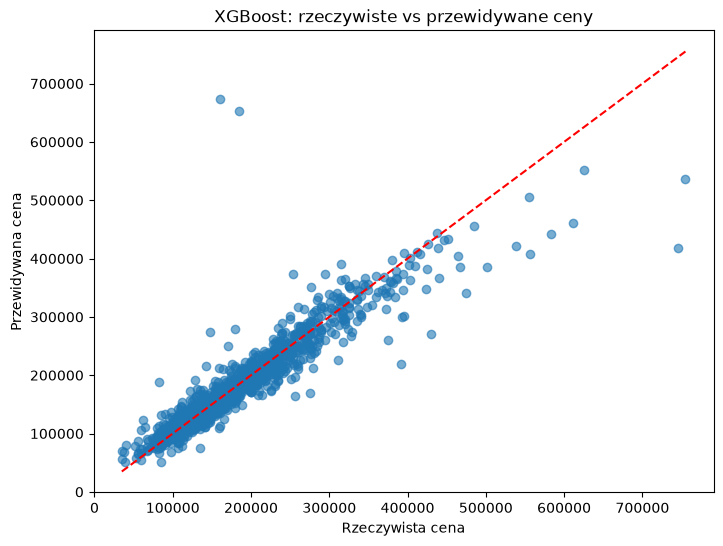

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y, y_pred, alpha=0.6)

# Idealne przewidywania: punkty leżą na tej linii
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Rzeczywista cena")
plt.ylabel("Przewidywana cena")
plt.title("XGBoost: rzeczywiste vs przewidywane ceny")
plt.show()

In [ ]:
error_df = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred
}, index=X.index)

error_df["Error"] = error_df["Predicted"] - error_df["Actual"]
error_df["Absolute Error"] = error_df["Error"].abs()

error_df["Percentage Error"] = (
    error_df["Absolute Error"] / error_df["Actual"] * 100
)

display(
    error_df.sort_values(
        "Absolute Error", ascending=False
    ).head(10)
)

,Actual,Predicted,Error,Absolute Error,Percentage Error
1298,160000,673197.18750,513197.18750,513197.18750,320.748242
523,184750,653825.50000,469075.50000,469075.50000,253.897429
1182,745000,418792.50000,-326207.50000,326207.50000,43.786242
691,755000,536182.68750,-218817.31250,218817.31250,28.982425
688,392000,219257.78125,-172742.21875,172742.21875,44.066893
496,430000,271135.81250,-158864.18750,158864.18750,36.945160
898,611657,460372.31250,-151284.68750,151284.68750,24.733582
1046,556581,407533.56250,-149047.43750,149047.43750,26.779110
803,582933,441509.15625,-141423.84375,141423.84375,24.260737
185,475000,340462.37500,-134537.62500,134537.62500,28.323711


In [ ]:
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])

xgb_final = TransformedTargetRegressor(
    regressor=xgb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

param_distributions = {
    "regressor__model__n_estimators": [400, 600, 800, 1000],
    "regressor__model__learning_rate": [0.02, 0.03, 0.04, 0.05],
    "regressor__model__max_depth": [2, 3, 4],
    "regressor__model__min_child_weight": [1, 3, 5],
    "regressor__model__subsample": [0.8, 0.9, 1.0],
    "regressor__model__colsample_bytree": [0.7, 0.8, 0.9],
    "regressor__model__reg_alpha": [0, 0.01, 0.1],
    "regressor__model__reg_lambda": [1, 3, 5]
}

random_search = RandomizedSearchCV(
    estimator=xgb_final,
    param_distributions=param_distributions,
    n_iter=20,
    scoring=rmsle_scorer,
    cv=kf,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

random_search.fit(X, y)

print("Najlepsze parametry:")
print(random_search.best_params_)

print("\nNajlepszy RMSLE:")
print(-random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Najlepsze parametry:
{'regressor__model__subsample': 0.8, 'regressor__model__reg_lambda': 3, 'regressor__model__reg_alpha': 0, 'regressor__model__n_estimators': 800, 'regressor__model__min_child_weight': 3, 'regressor__model__max_depth': 3, 'regressor__model__learning_rate': 0.04, 'regressor__model__colsample_bytree': 0.7}

Najlepszy RMSLE:
0.12471919053764195


In [ ]:
final_model = random_search.best_estimator_
final_model.fit(X,y)
test_predictions = final_model.predict(X_test)
submission = pd.DataFrame({
    "Id" : test_csv["Id"],
    "SalePrice" : np.maximum(test_predictions, 0)
})
submission.to_csv("../data/submission.csv", index=False)
display(submission.head())

,Id,SalePrice
0,1461,125259.585938
1,1462,160204.234375
2,1463,184467.078125
3,1464,195162.125000
4,1465,190936.484375
